# Какие кадры из Reels помогают найти место?

Передаём путь к скачанному видео в `ranker.rank_video(video_path)`. EmbeddingGemma 2 сравнивает кадры с пятью общими описаниями подсказок: вывески, указатели, приметные здания, подписи с названиями и природные ориентиры. Сохраняем крайние десятки, вариант с фильтром повторов и замеры времени на CPU.

Для воспроизведения используйте Python 3.12. В окружении ядра выполните из корня репозитория:

```sh
python -m pip install torch==2.15.0 torchvision==0.29.2 --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r research/notebooks/requirements-gemma-frames.txt
```

Скопируйте [образец настроек](../../.env.example) в `.env` в корне репозитория. Укажите каталог видео и пять относительных имён файлов. При удалённом запуске пути к видео, весам и результатам должны быть доступны **ядру на сервере**. Идентификатор модели в образце скачает зафиксированную версию при первом запуске. Для работы без сети можно указать каталог с этой же версией весов. [Модель Google](https://huggingface.co/google/embeddinggemma-2/tree/f9972ac22e696a105c482202646979e33e4b5a1e).


In [1]:
import io
import json
import os
import sys
from pathlib import Path

from dotenv import load_dotenv
from IPython.display import HTML, Image as NotebookImage, display
from html import escape

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/gemma_frames.py").is_file())
sys.path.insert(0, str(root))
import warnings
# В терминальном ядре виджеты прогресса не используются.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.autonotebook")
    warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")
    from src.gemma_frames import FrameRanker, MODEL_ID, contact_sheet

load_dotenv(root / ".env")
video_dir = root / os.environ["REELS_VIDEO_DIR"]
videos = [video_dir / item for item in json.loads(os.environ["REELS_VIDEO_FILES"])]
if not videos or len(set(v.resolve() for v in videos)) != len(videos) or not all(v.is_file() for v in videos):
    raise ValueError("Проверьте список в .env: нужны существующие файлы без повторов, доступные из ядра.")
print(f"Проверены исходные видео: {len(videos)}.")



Проверены исходные видео: 5.


## Загрузка модели на CPU

Модель и текстовые запросы загружаются один раз на всю выборку. Первый кадр каждой секунды оцениваем в FP32 с бюджетом 140 визуальных токенов. Скор кадра — максимальное косинусное сходство с пятью запросами.

In [2]:
weights = os.getenv("GEMMA_MODEL", MODEL_ID)
if weights != MODEL_ID:
    weights = root / weights
ranker = FrameRanker(
    output_dir=root / os.getenv("REELS_OUTPUT_DIR", "outputs/gemma_frames"),
    model_path=weights,
    threads=int(os.getenv("GEMMA_CPU_THREADS", "3")),
)
print(f"Модель и запросы готовы за {ranker.setup_seconds:.1f} с; CPU-потоков: {ranker.threads}.")

Модель и запросы готовы за 4.2 с; CPU-потоков: 3.


## Обработка пяти скачанных видео

Для отдельного ролика достаточно вызова `ranker.rank_video(video_path)`. Функция возвращает каталог с JPEG и `results.json`. В каждом запуске создаётся новый каталог, поэтому несколько файлов с одинаковым именем не перезаписывают результаты друг друга.

In [3]:
runs = []
for video_path in videos:
    run_dir = ranker.rank_video(video_path)
    report = json.loads((run_dir / "results.json").read_text(encoding="utf-8"))
    runs.append((run_dir, report))
    print(f"{report['video']}: {report['metrics']['candidates']} кадров")

De2M3kBN9Uf: 53 кадров
De4IKljoBfq: 53 кадров
De56UsuT0HW: 42 кадров
DfAKNCvNDX5: 103 кадров
DfQLrCFtOJH: 94 кадров


## Сколько времени занимает один ролик

Все времена приведены в секундах. «Всего» — прошедшее время от начала обработки файла до готового рейтинга, включая FFmpeg. «Инференс» включает чтение JPEG, подготовку входа и кодирование изображений. CPU·с — сумма процессорного времени потоков Python-процесса за этот же этап. Общая для пяти видео загрузка модели показана выше.

In [4]:
from statistics import median

metrics = [report["metrics"] for _, report in runs]
headers = ["Ролик", "Кадры", "FFmpeg, с", "Инференс, с", "CPU·с", "Всего, с", "с/кадр"]
rows = []
for (_, report), m in zip(runs, metrics):
    rows.append([report["video"], m["candidates"], m["decode_s"], m["encode_s"],
                 m["encode_cpu_s"], m["wall_s"], m["s_per_frame"]])

def cell_text(value):
    return f"{value:.2f}" if isinstance(value, float) else escape(str(value))

display(HTML("<table><tr>" + "".join(f"<th>{h}</th>" for h in headers) + "</tr>"
             + "".join("<tr>" + "".join(f"<td>{cell_text(v)}</td>" for v in row) + "</tr>" for row in rows)
             + "</table>"))
print(f"Всего {sum(m['candidates'] for m in metrics)} кадров; "
      f"обработка файлов заняла {sum(m['wall_s'] for m in metrics):.1f} с. "
      f"Медиана с/кадр по роликам: {median(m['s_per_frame'] for m in metrics):.2f}.")

Ролик,Кадры,"FFmpeg, с","Инференс, с",CPU·с,"Всего, с",с/кадр
De2M3kBN9Uf,53,1.48,185.52,549.20,187.00,3.50
De4IKljoBfq,53,1.61,185.07,547.68,186.68,3.49
De56UsuT0HW,42,1.39,148.07,438.68,149.46,3.53
DfAKNCvNDX5,103,2.30,367.02,1084.85,369.32,3.56
DfQLrCFtOJH,94,2.15,332.69,984.25,334.84,3.54


Всего 345 кадров; обработка файлов заняла 1227.3 с. Медиана с/кадр по роликам: 3.53.


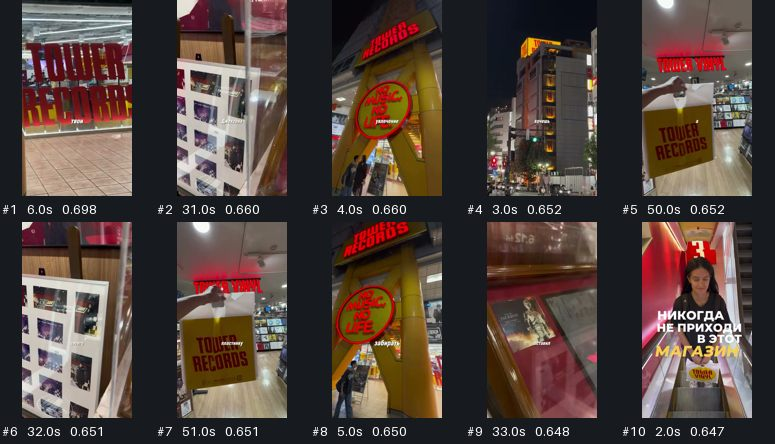

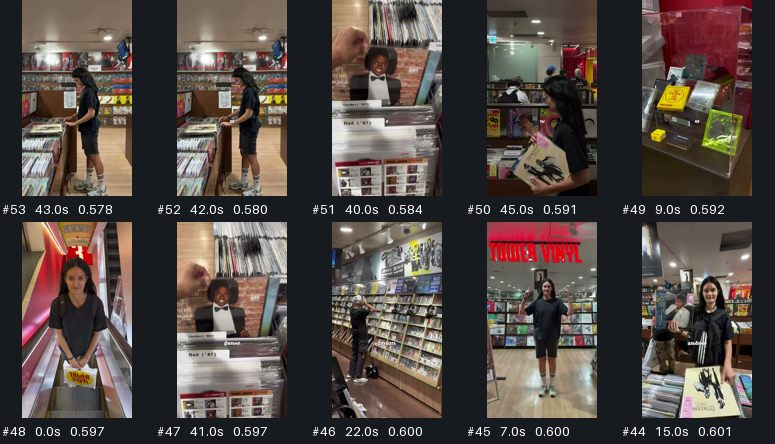

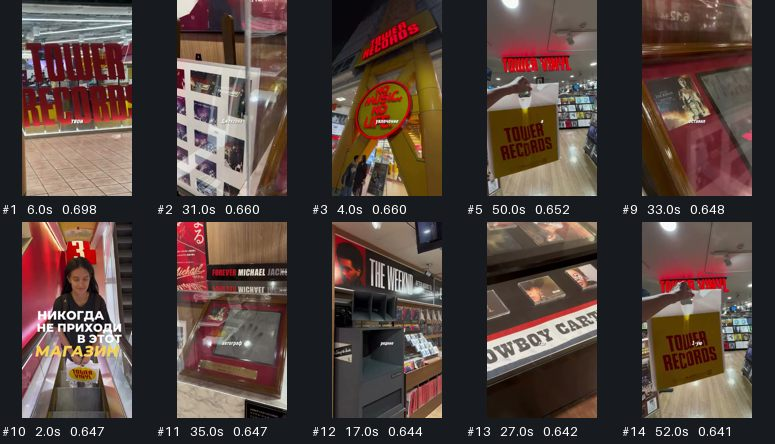

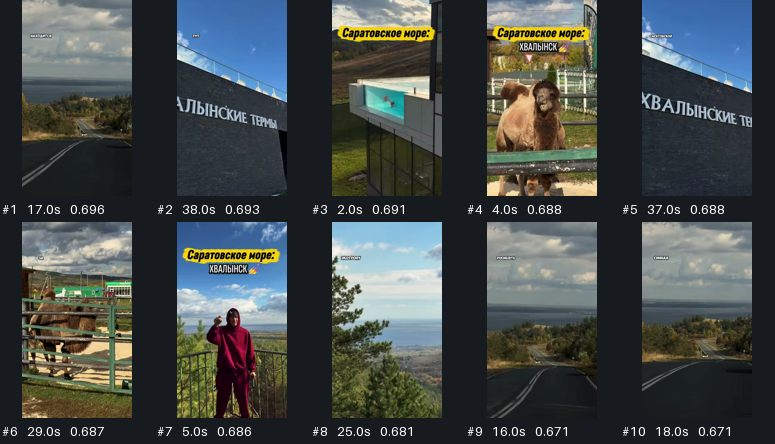

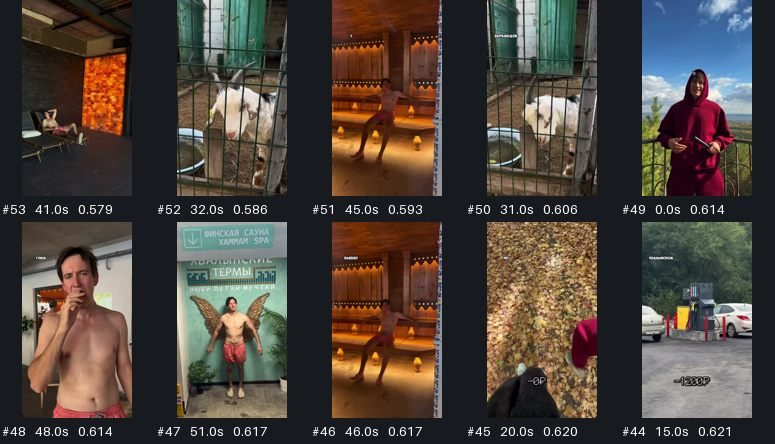

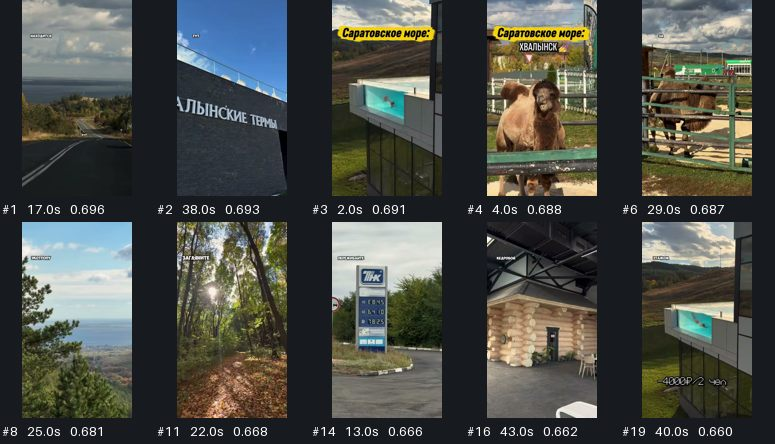

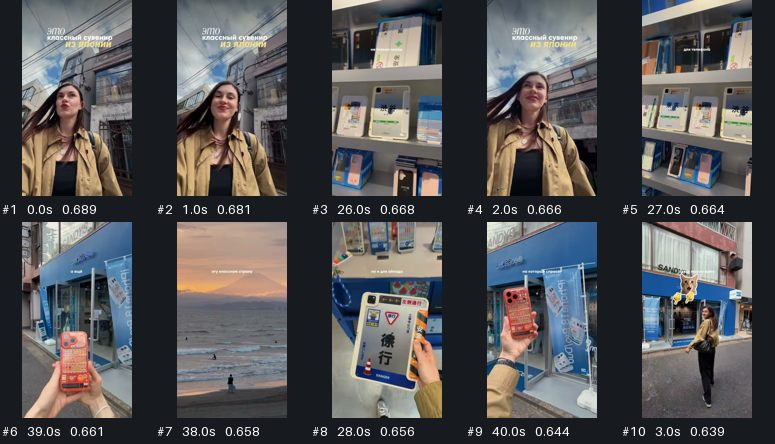

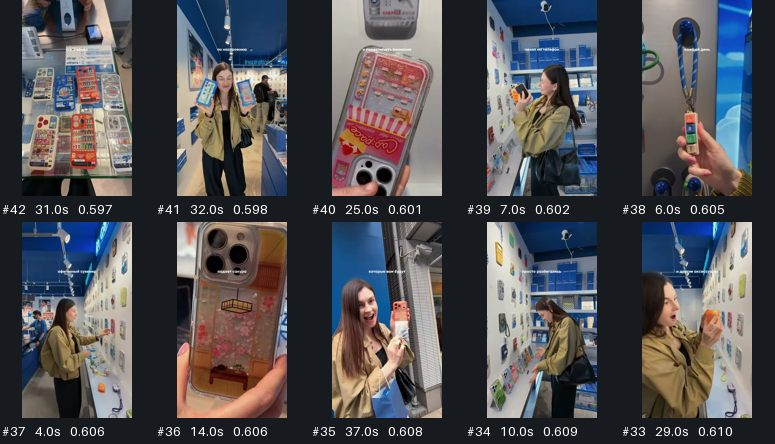

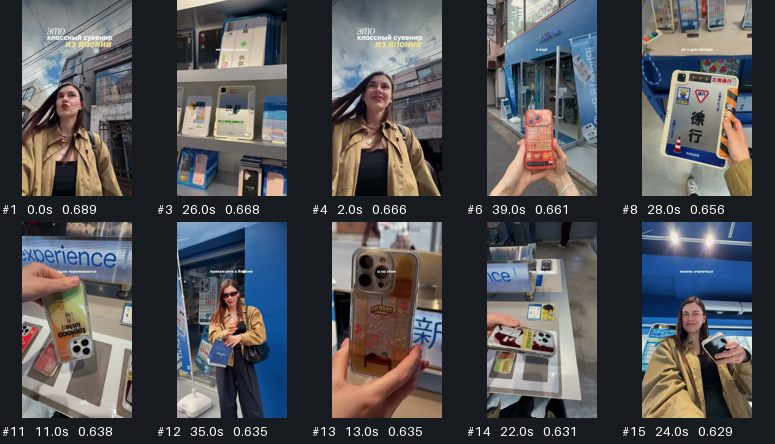

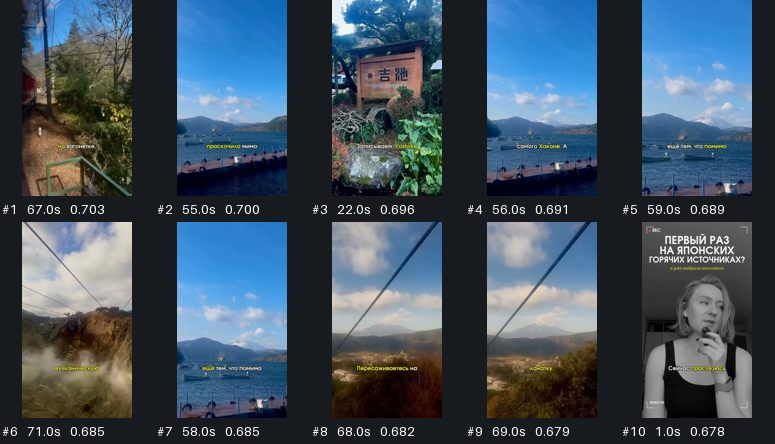

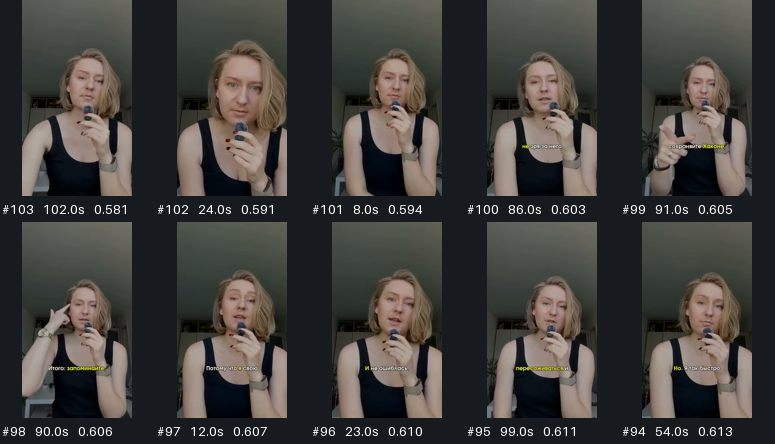

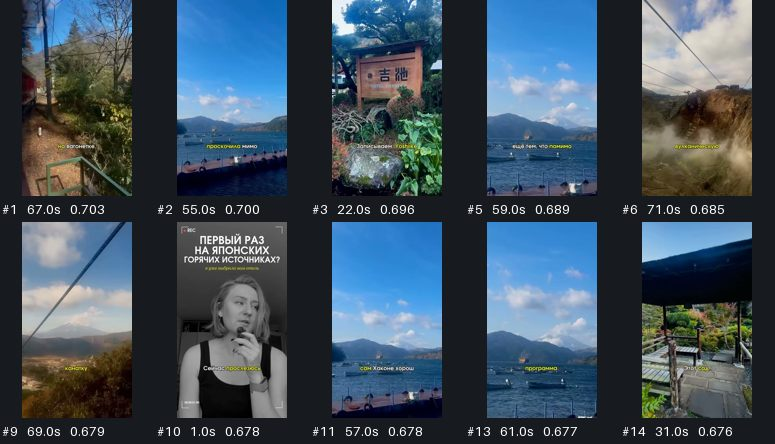

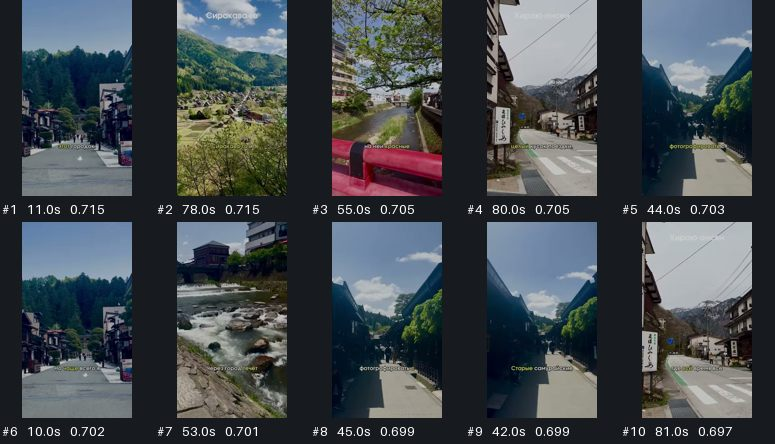

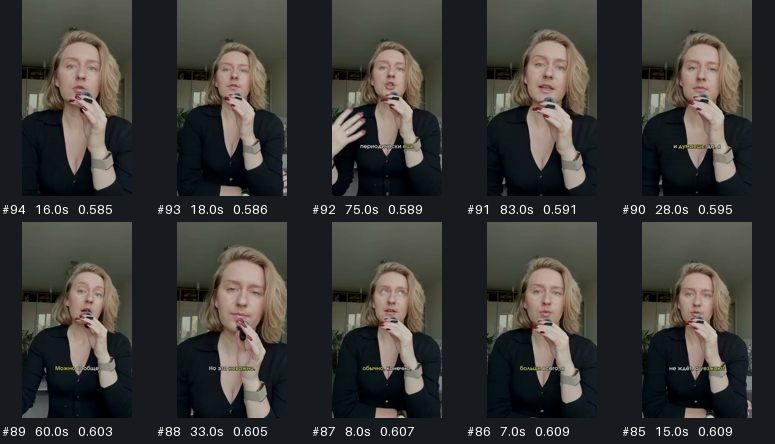

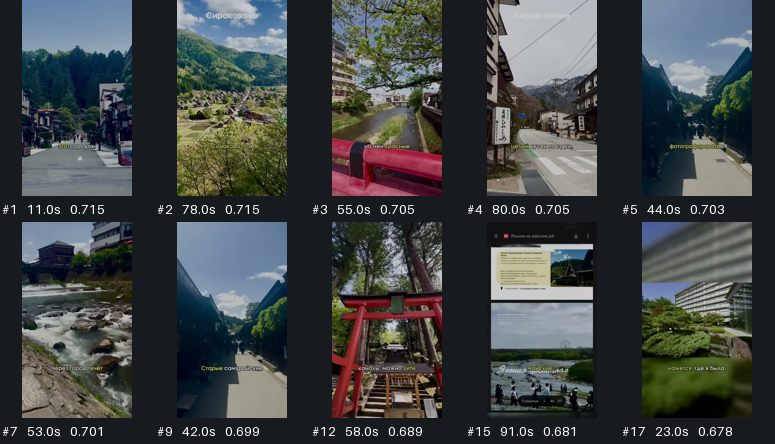

In [5]:
for run_dir, report in runs:
    display(HTML(f"<h3>{escape(report['video'])}</h3>"))
    for key, title in [("top", "Верхние оценки"), ("bottom", "Нижние оценки"),
                       ("diverse", "Верхние оценки после фильтра повторов")]:
        display(HTML(f"<b>{title}</b>"))
        panel = contact_sheet(run_dir, report[key])
        data = io.BytesIO()
        panel.save(data, "JPEG", quality=81)
        display(NotebookImage(data=data.getvalue()))

## Что показали пять роликов

На CPU Intel Xeon Gold 5220R при трёх потоках 345 кадров заняли 20 мин 27 с без разовой загрузки модели. Время инференса на кадр лежало в пределах 3,49–3,56 с (среднее внутри каждого ролика). При одном кадре в секунду минутный ролик требует примерно 3,5 минуты обработки в этой конфигурации.

В ролике про магазин пластинок первым оказался кадр с вывеской TOWER RECORDS. В ролике про сувенир первыми оказались два почти одинаковых кадра ведущей с надписью. Высокий скор помогает найти кадр для дальнейшего просмотра, но сам по себе не подтверждает название места. Для оценки качества отбора нужна разметка интервалов, где место можно опознать.

В каждом наборе подпись под изображением показывает исходный ранг, таймкод и скор. Фильтр повторов оставляет до десяти кадров с интервалом от двух секунд и сходством между выбранными кадрами ниже 0,965. Полный рейтинг и времена сохраняются в `results.json` в каталоге, который возвращает функция. На Linux-сервере с подготовленными томами окружения и весов повторный запуск из корня проекта — `sh src/run_gemma_notebook.sh`. Параметры этого режима перечислены в `.env.example`.
